A continuación, se va a aplicar el filtro de kalman al caso del péndulo. Para poder linealizar el sistema y poder aplicar el filtro de Kalman, se realiza la aproximación de pequeños ángulos.

In [1]:
import numpy as np

from particle_filter.filtering_algorithms.kalman_filter import KalmanFilter

from particle_filter.filtering_algorithms.particle_filter import BootstrapParticleFilter, AuxiliaryParticleFilter

from particle_filter.models.noise import GaussianNoise
from particle_filter.models.transition import AdditiveTransitionModel
from particle_filter.models.observation import AdditiveObservationModel

from particle_filter.simulations import system_simulation

from particle_filter.plots.plot_results import plot_results

C:\Users\usuario\Desktop\Particle_Filter\particle_filter\models\transition.py:4: SyntaxWarning: invalid escape sequence '\s'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\models\transition.py:15: SyntaxWarning: invalid escape sequence '\s'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\models\transition.py:22: SyntaxWarning: invalid escape sequence '\m'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\models\observation.py:4: SyntaxWarning: invalid escape sequence '\s'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\models\observation.py:14: SyntaxWarning: invalid escape sequence '\s'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\models\observation.py:21: SyntaxWarning: invalid escape sequence '\m'
  """


# PENDULO
Un péndulo (sin control) suele modelarse en espacio de estados como:

$$
x = 
\begin{bmatrix}
\theta \\
\omega
\end{bmatrix}
$$

con 
- $\theta$: ángulo
- $\omega$: velocidad angular

Ecuación continua:

$$
\dot{\theta} = \omega \\
\dot{\omega} = -\frac{g}{L}sin(\theta)
$$

### Discretización
Dado que se trabaja con el tiempo discreto, se necesita realizar una aproximación numérica. En este caso se ha tomado Euler.

La idea es aproximar las derivadas como:

$$
x´(t)\approx \frac{x_{n+1} - x_n}{\Delta t} 
$$

y despejando:

$$
x_{n+1} = x_n + \Delta t \;x´(t_n)
$$

Por lo tanto, tras la discretización, las ecuacciones del péndulo quedan:

$$
\theta_{n+1} = \theta_{n} + \Delta t\;w_n \\
w_{n+1} = w_n - \Delta t\; \frac{g}{L}\;sin(\theta_n)
$$

Depende mucho del valor de $\Delta_t$ y no conservar la energía provocando que el péndulo gane energía artificial (oscilaciones cada vez más grandes) o perder energía (amortiguamiento artificial).

### Observación

En este ejemplo se tiene el caso en el que solamente se mide el ángulo:

$$
y_t = \theta_t + v_t
$$

### Ecuación en espacio de estados

Finalmente, el modelo en espacio de estados tiene la siguiente forma

- Vector estado

$$
x_k = \begin{bmatrix}
\theta_k \\
\omega_k
\end{bmatrix}
$$

- Modelo dinámico 

$$
x_{k+1} = \begin{bmatrix}
\theta_k + \omega_k\; \Delta_t \\
\omega_k - \frac{g}{L}\;sin(\theta_k)\;\Delta_t
\end{bmatrix}
+ w_k
$$

- Modelo de medición

$$
y_k = \begin{bmatrix} 1 &0 \end{bmatrix} x_k + v_k
$$

con 

$$
w_k \sim \mathcal{N}(0, Q)\quad \quad v_k \sim \mathcal{N}(0, R)\\\\[2ex]

Q = \begin{bmatrix}

10^{-4} &0\\
0 &10^{-3}
\end{bmatrix}

\quad \quad

R = \begin{bmatrix} 10^{-2} \end{bmatrix}
$$

### Aproximación ángulos pequeños

Para poder linealizar el sistema y poder aplicar el filtro de Kalman, se realiza la aproximación para ángulos pequeños

$$
sin(\theta) \approx \theta
$$

Entonces

$$
\dot{\theta}= w \quad\quad\quad \dot{w} = -\frac{g}{L}\theta
$$

La aproximación de Euler

$$
A =
\begin{bmatrix}
1 &dt\\
-\frac{g}{L}\cdot dt &1
\end{bmatrix}
$$

Por lo tanto, el modelo en espacio de estados para el caso del filtro de Kalman es:

- Vector estado

$$
x_k = \begin{bmatrix}
\theta_k \\
\omega_k
\end{bmatrix}
$$

- Modelo dinámico 

$$
x_{k+1} = \begin{bmatrix}
\theta_k + \omega_k\; \Delta_t \\
\omega_k - \frac{g}{L}\;\theta_k\;\Delta_t
\end{bmatrix}
+ w_k
$$

- Modelo de medición

$$
y_k = \begin{bmatrix} 1 &0 \end{bmatrix} x_k + v_k
$$

con 

$$
w_k \sim \mathcal{N}(0, Q)\quad \quad v_k \sim \mathcal{N}(0, R)\\\\[2ex]

Q = \begin{bmatrix}

10^{-4} &0\\
0 &10^{-3}
\end{bmatrix}

\quad \quad

R = \begin{bmatrix} 10^{-2} \end{bmatrix}
$$

In [2]:
# Parámetros péndulo
g = 9.81
L = 1.0

# Paso de tiempo (discretización)
dt = 0.01

- Definición del estado para filtro de partículas

In [3]:
# Definición función de transición
def f(x):
    theta, omega = x

    omega_dot = -(g / L) * np.sin(theta)

    theta_next = theta + omega * dt
    omega_next = omega + omega_dot * dt

    theta_next = (theta_next + np.pi) % (2*np.pi) - np.pi

    return np.array([theta_next, omega_next])


# Definición función de medición 
def h(x):
    theta, _ = x

    return np.array([theta])

In [4]:
# Definicion de ruidos(el mismo para el filtro de Kalman)
Q = np.diag([1e-4, 1e-3]) #ruido de proceso
R = np.array([[1e-2]]) #ruido medicion

In [5]:
# Definición modelos
noise_transition = GaussianNoise(Q)
transition = AdditiveTransitionModel(f, noise_transition)

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation)

- Definición matrices de estado para el filtro de Kalman

In [6]:
# Matriz transición
A = np.array([
    [1, dt],
    [-(g/L)*dt, 1]
])

# Matriz obsevación
H = np.array([[1, 0]])

A continuación, se van a ejecutar el filtado con el Kalman Filter, Bootstrap Particle Filter y Auxiliary Particle Filter (estos dos últimos con re-muestreo) para diferentes ángulos iniciales.

Para cada caso, en los modelos de filtrado se considera que se conoce el estado inicial con el ángulo de cada caso y con velocidad angular nula:

$$
x_0 = \begin{bmatrix}
\theta_0 \\
0
\end{bmatrix}
$$

y la incertidumbre inicial se elige pequeña.

$$
P_0 = \begin{bmatrix}
\sigma_\theta^2 &0\\
0 &\sigma_\omega^2
\end{bmatrix}
$$

con 

$$
\sigma_\theta = 1º \quad\quad\quad \sigma_\omega = 0.05\; rad/s
$$

Así el filtro de Kalman se inicializa con media $x_0$ y covarianza $P_0$. 

El filtro de partículas (con pesos uniformes) genera las partículas iniciles según 

$$
x_0^{(i)} \sim \mathcal{N}(x_0, P_0)\quad i=1,...,N
$$

In [7]:
P0 = np.diag([
    np.deg2rad(1)**2,
    0.05**2
])

### Caso 1: Ángulo inicial 5º

In [8]:
# Simulación
T = 500
x0 = np.array([
    np.deg2rad(5), # 5 grados iniciales
    0.0            # sin velocidad inicial 
])

x_true, y_obs = system_simulation(transition, observation, x0, T)

In [9]:
# Inicializacion modelos
bpf = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

bpf.initialize(mean=x0, cov=P0)

apf = AuxiliaryParticleFilter(
    N=1000, 
    transition_model=transition,
    observation_model=observation
)

apf.initialize(mean=x0, cov=P0)

kf = KalmanFilter(A, H, Q, R, x0, P0)

In [10]:
# Ejecucion filtrados
est_bpf = bpf.run_filter(y_obs, resample_threshold=(bpf.N)/2)
print("Bootstrap Particle Filter finalizado")

est_apf = apf.run_filter(y_obs, resample_threshold=(apf.N)/2)
print("Auxiliary Particle Filter finalizado")

est_kf = kf.run_filter(y_obs)
print("Kalman Filter finalizado")

Bootstrap Particle Filter finalizado
Auxiliary Particle Filter finalizado
Kalman Filter finalizado


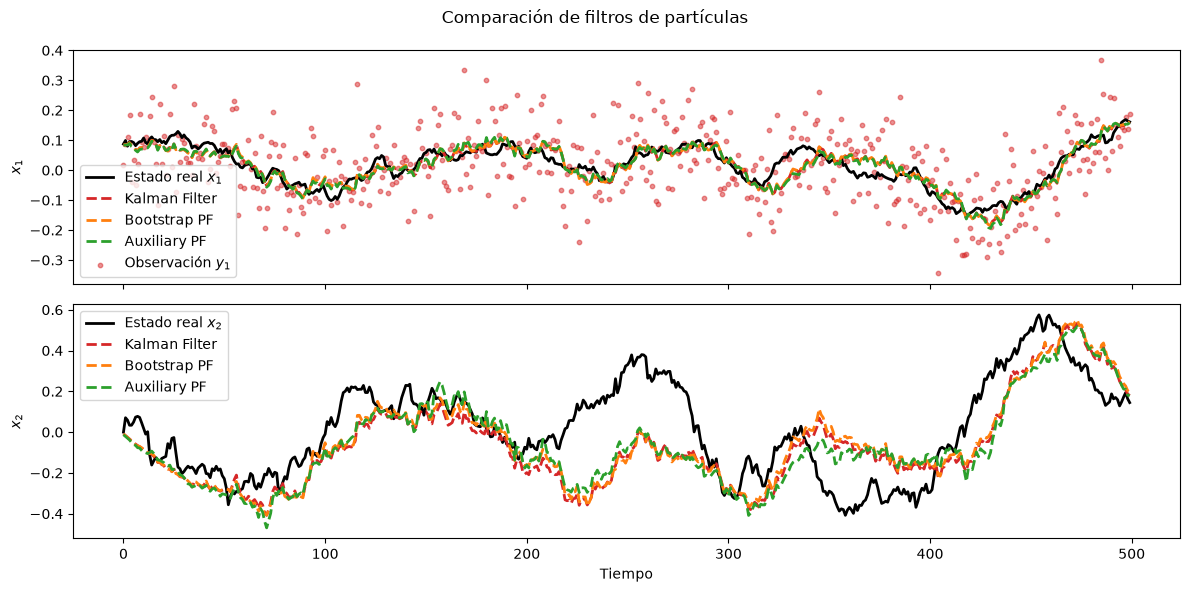

In [11]:
# Plot resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"],
}

plot_results(x_true, y_obs, estimates)

### Caso 1: Ángulo inicial 15º

In [ ]:
# Simulación
T = 500
x0 = np.array([
    np.deg2rad(15), # 15 grados iniciales
    0.0            # sin velocidad inicial 
])

x_true, y_obs = system_simulation(transition, observation, x0, T)

In [43]:
# Ejecucion filtrados
bpf.reset(x0, P0)
est_bpf = bpf.run_filter(y_obs, resample_threshold=(bpf.N)/2)
print("Bootstrap Particle Filter finalizado")

apf.reset(x0, P0)
est_apf = apf.run_filter(y_obs, resample_threshold=(apf.N)/2)
print("Auxiliary Particle Filter finalizado")

kf.reset(x0, P0)
est_kf = kf.run_filter(y_obs)
print("Kalman Filter finalizado")

Bootstrap Particle Filter finalizado
Auxiliary Particle Filter finalizado
Kalman Filter finalizado


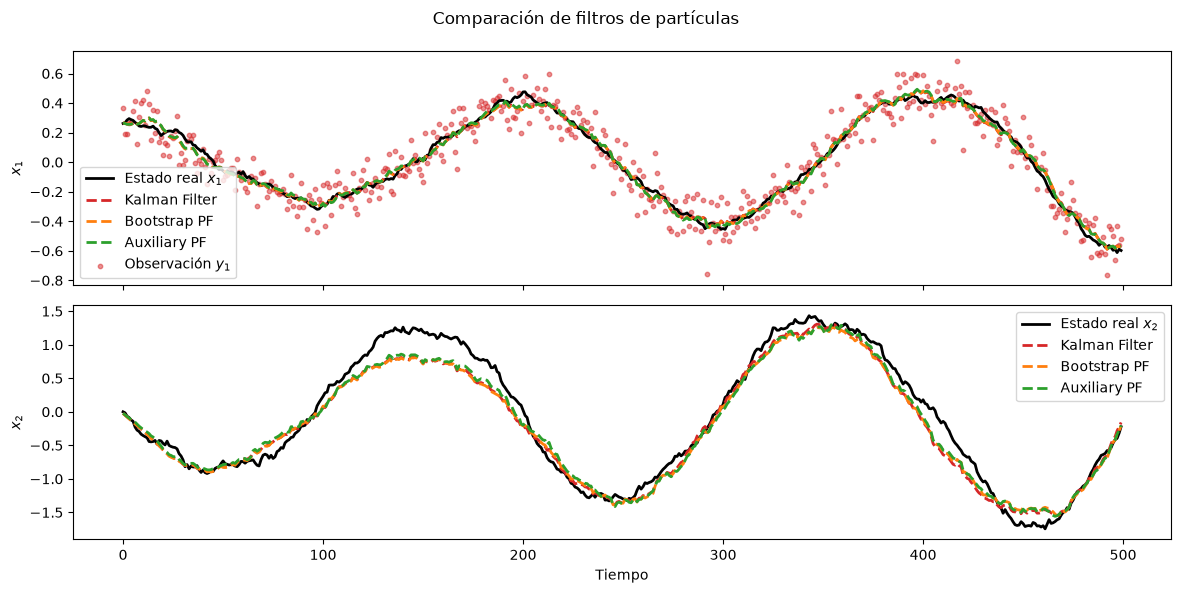

In [44]:
# Plot resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"],
}

plot_results(x_true, y_obs, estimates)

### Caso 1: Ángulo inicial 45º

In [45]:
# Simulación
x0 = np.array([
    np.deg2rad(45), # 45 grados iniciales
    0.0            # sin velocidad inicial 
])

x_true, y_obs = system_simulation(transition, observation, x0, T)

In [46]:
# Ejecucion filtrados
bpf.reset(x0, P0)
est_bpf = bpf.run_filter(y_obs, resample_threshold=(bpf.N)/2)
print("Bootstrap Particle Filter finalizado")

apf.reset(x0, P0)
est_apf = apf.run_filter(y_obs, resample_threshold=(apf.N)/2)
print("Auxiliary Particle Filter finalizado")

kf.reset(x0, P0)
est_kf = kf.run_filter(y_obs)
print("Kalman Filter finalizado")

Bootstrap Particle Filter finalizado
Auxiliary Particle Filter finalizado
Kalman Filter finalizado


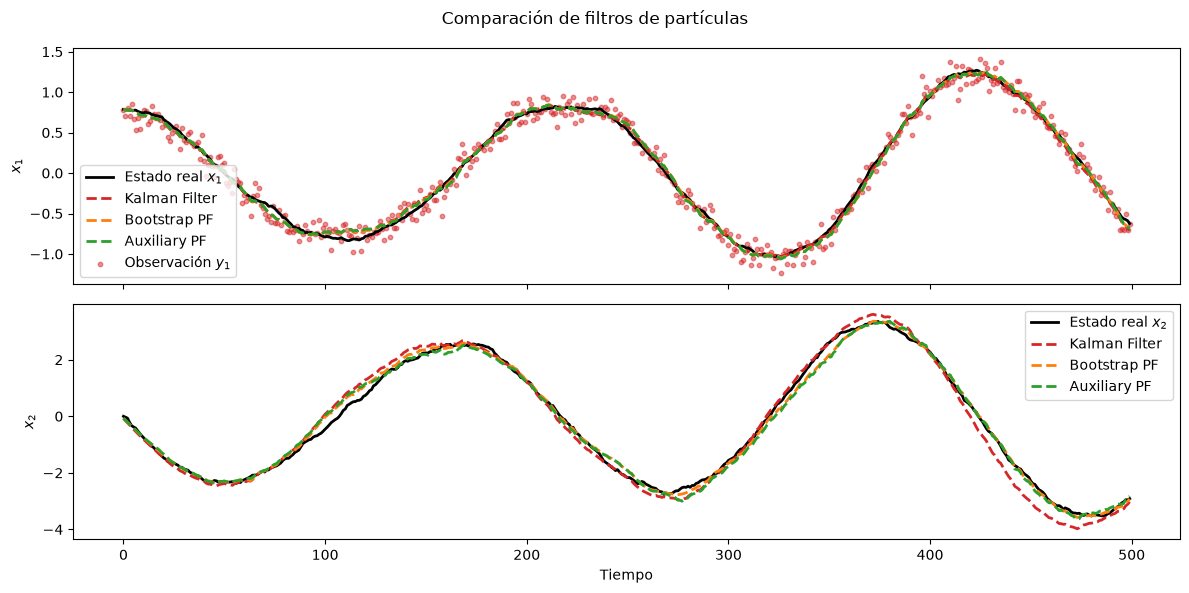

In [47]:
# Plot resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"],
}

plot_results(x_true, y_obs, estimates)

### Caso 4: Ángulo inicial 90º

In [49]:
# Simulación
x0 = np.array([
    np.deg2rad(90), # 90 grados iniciales
    0.0            # sin velocidad inicial 
])

x_true, y_obs = system_simulation(transition, observation, x0, T)

In [50]:
# Ejecucion filtrados
bpf.reset(x0, P0)
est_bpf = bpf.run_filter(y_obs, resample_threshold=(bpf.N)/2)
print("Bootstrap Particle Filter finalizado")

apf.reset(x0, P0)
est_apf = apf.run_filter(y_obs, resample_threshold=(apf.N)/2)
print("Auxiliary Particle Filter finalizado")

kf.reset(x0, P0)
est_kf = kf.run_filter(y_obs)
print("Kalman Filter finalizado")

Bootstrap Particle Filter finalizado
Auxiliary Particle Filter finalizado
Kalman Filter finalizado


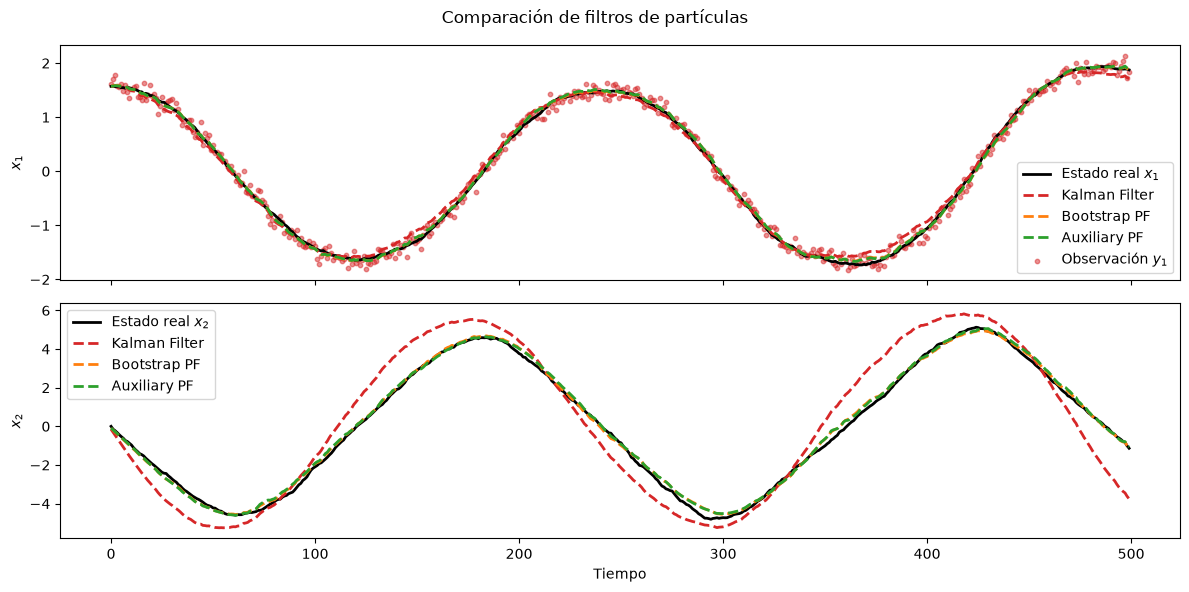

In [ ]:
# Plot resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"],
}

plot_results(x_true, y_obs, estimates)

### Caso 5: Ángulo inicial 120º

In [60]:
# Simulación
x0 = np.array([
    np.deg2rad(120), # 120 grados iniciales
    0.0            # sin velocidad inicial 
])

x_true, y_obs = system_simulation(transition, observation, x0, T)

In [61]:
# Ejecucion filtrados
bpf.reset(x0, P0)
est_bpf = bpf.run_filter(y_obs, resample_threshold=(bpf.N)/2)
print("Bootstrap Particle Filter finalizado")

apf.reset(x0, P0)
est_apf = apf.run_filter(y_obs, resample_threshold=(apf.N)/2)
print("Auxiliary Particle Filter finalizado")

kf.reset(x0, P0)
est_kf = kf.run_filter(y_obs)
print("Kalman Filter finalizado")

Bootstrap Particle Filter finalizado
Auxiliary Particle Filter finalizado
Kalman Filter finalizado


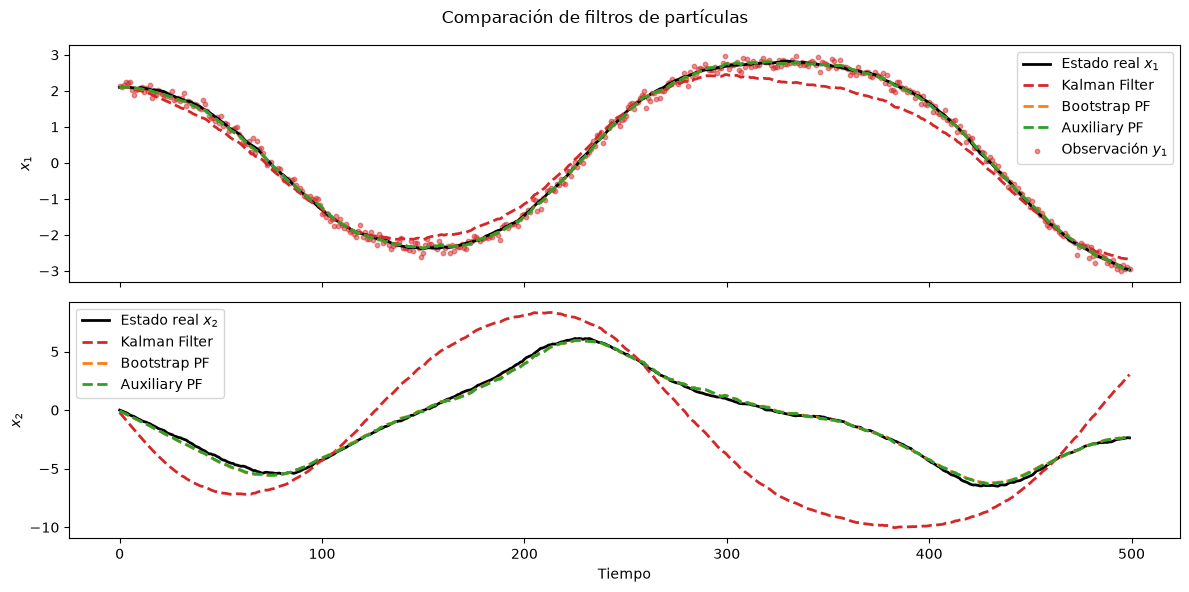

In [62]:
# Plot resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"],
}

plot_results(x_true, y_obs, estimates)

### Caso 5: Ángulo inicial 180º

In [63]:
# Simulación
x0 = np.array([
    np.deg2rad(180), # 120 grados iniciales
    0.0            # sin velocidad inicial 
])

x_true, y_obs = system_simulation(transition, observation, x0, T)

In [64]:
# Ejecucion filtrados
bpf.reset(x0, P0)
est_bpf = bpf.run_filter(y_obs, resample_threshold=(bpf.N)/2)
print("Bootstrap Particle Filter finalizado")

apf.reset(x0, P0)
est_apf = apf.run_filter(y_obs, resample_threshold=(apf.N)/2)
print("Auxiliary Particle Filter finalizado")

kf.reset(x0, P0)
est_kf = kf.run_filter(y_obs)
print("Kalman Filter finalizado")

Bootstrap Particle Filter finalizado
Auxiliary Particle Filter finalizado
Kalman Filter finalizado


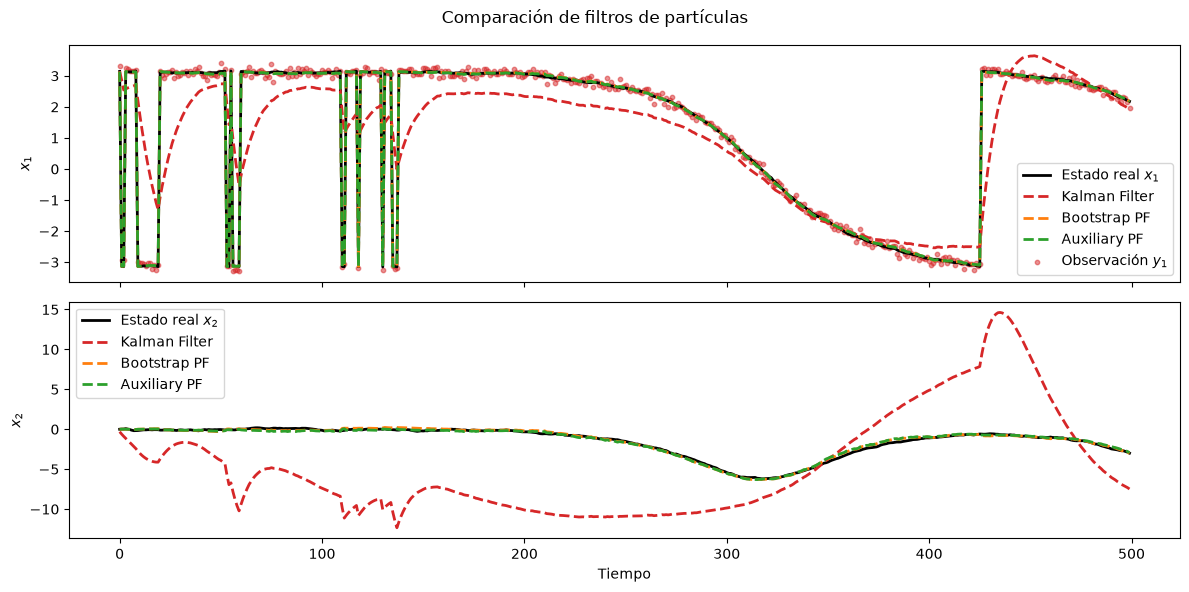

In [65]:
# Plot resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"],
}

plot_results(x_true, y_obs, estimates)